<a href="https://colab.research.google.com/github/sidagarwal-labs/LLMs/blob/main/00_pytorch_basics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 00 · PyTorch basics

Milestone 1, roadmap step 0 · tracked in [issue #4](https://github.com/sidagarwal-labs/LLMs/issues/4)

**Tutorial used:** [PyTorch Tensors tutorial](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html) (replace or add links as you go)

**Where this leads:** [the three-stage learning path](https://github.com/sidagarwal-labs/LLMs/blob/main/docs/learning-path.md). This notebook teaches weight updates; hidden-law experiments and RL come later.

**How to use this notebook**

- These cells are prompts, not solutions. Write the code yourself.
- Before running a cell, write down what you expect: the shape, the value, or the error. Then run it and compare.
- A CPU runtime is enough. You don't need a GPU until GPT training.
- When you're done, restart the runtime, run all cells, and use **File > Save a copy to GitHub** to save to `notebooks/00_pytorch_basics.ipynb` on `main`.

## Environment

Run this cell as-is. It records what you ran on, so results are reproducible.

In [158]:
import sys
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Python: 3.13.18
PyTorch: 2.14.1+cpu
CUDA available: False


## 1. Tensors: shape, data type, and device

Create a tensor with shape `(2, 3)` from a nested Python list. Print its `shape`, `dtype`, and `device`.

- **Prediction:** what `dtype` do you expect if every value is a whole number? What if one value is `1.5`?
- Then create the same shape with `torch.zeros`, `torch.ones`, and `torch.rand`.

As expected, whole numbers are integers 64 bit

In [159]:
# Your code here
x = torch.tensor([
    [1, 2, 3],
    [4, 5, 6]
])

print(x)
print(x.shape)
print(x.dtype)
print(x.device)

tensor([[1, 2, 3],
        [4, 5, 6]])
torch.Size([2, 3])
torch.int64
cpu


Interestingly, having 1.5 turns all the x values into floats. Returning 1.5000, 2.0000, etc.

In [160]:
x_float = torch.tensor([
    [1.5, 2, 3],
    [4,   5, 6],
])

print(x_float)
print("Shape:", x_float.shape)
print("Data type:", x_float.dtype)
print("Device:", x_float.device)

tensor([[1.5000, 2.0000, 3.0000],
        [4.0000, 5.0000, 6.0000]])
Shape: torch.Size([2, 3])
Data type: torch.float32
Device: cpu


In [161]:
zeros = torch.zeros(2, 3)
ones = torch.ones(2, 3)
random_values = torch.rand(2, 3)

print("Zeros:")
print(zeros)

print("Ones:")
print(ones)

print("Random values:")
print(random_values)

Zeros:
tensor([[0., 0., 0.],
        [0., 0., 0.]])
Ones:
tensor([[1., 1., 1.],
        [1., 1., 1.]])
Random values:
tensor([[0.2485, 0.4482, 0.0046],
        [0.4001, 0.3850, 0.2290]])


**What happened vs. what I predicted:**

## 2. Indexing, reshaping, and broadcasting

Using your `(2, 3)` tensor:

1. Select the second row, then the last column. Predict each result's shape first.
2. Reshape it to `(3, 2)` and then to `(6,)`. Is the order of the values what you expected?
3. Add a tensor with shape `(3,)`. Predict the result's shape (this is broadcasting).
4. Find a shape pair that **fails** to broadcast. Read the error message.

**Explain the failing case in your own words:** why could PyTorch not line the shapes up?

In [162]:
second_row = x[1]

print(second_row)
print(second_row.shape)

tensor([4, 5, 6])
torch.Size([3])


In [163]:
last_column = x[:, -1]

print(last_column)
print(last_column.shape)

tensor([3, 6])
torch.Size([2])


In [164]:
reshaped = x.reshape(3, 2)

print(reshaped)

tensor([[1, 2],
        [3, 4],
        [5, 6]])


In [165]:
flat = x.reshape(6)

print(flat)
print(flat.shape)

tensor([1, 2, 3, 4, 5, 6])
torch.Size([6])


In [166]:
offsets = torch.tensor([10, 20, 30])

result = x + offsets

print(result)
print(result.shape)

tensor([[11, 22, 33],
        [14, 25, 36]])
torch.Size([2, 3])


Below fails due to difference in tensor size. X is a (2, 3), bad_offset is (2, )

In [167]:
#bad_offsets = torch.tensor([10, 20])

#print(x + bad_offsets)

Below works because X is (2, 3) and offsets is (2, 1)

In [168]:
row_offsets = torch.tensor([
    [10],
    [20],
])

print(row_offsets.shape)
print(x + row_offsets)

torch.Size([2, 1])
tensor([[11, 12, 13],
        [24, 25, 26]])


## 3. Matrix multiplication

1. Multiply a `(2, 3)` matrix by a `(3, 2)` matrix with `@`. **Predict the output shape before running.**
2. Now try `(3, 2) @ (2, 3)`. Predict the shape again.
3. What is the difference between `a * b` and `a @ b`? Show one example where `*` works and `@` fails, or the reverse.

In [169]:
# Your code here
a = torch.tensor([
    [1, 2, 3],
    [4, 5, 6],
])

b = torch.tensor([
    [7,  8],
    [9, 10],
    [11, 12],
])

print("a:", a.shape)
print("b:", b.shape)

a: torch.Size([2, 3])
b: torch.Size([3, 2])


In [170]:
result = a @ b

print(result)
print(result.shape)

tensor([[ 58,  64],
        [139, 154]])
torch.Size([2, 2])


A (2, 3) matrix times a (3, 2) matrix is a (2, 2) matrix. This is done by taking the outside numbers. The inside numbers (3) must match.



*   58 --> 1*7 + 2*9 + 3*11 = 7+18+33 = 58
*   64 --> 1*8 + 2*10 + 3*12 = 8 + 20 + 36 = 64

In [171]:
reversed_result = b @ a

print(reversed_result)
print(reversed_result.shape)

tensor([[ 39,  54,  69],
        [ 49,  68,  87],
        [ 59,  82, 105]])
torch.Size([3, 3])


In [172]:
print(a * a)

tensor([[ 1,  4,  9],
        [16, 25, 36]])


Expression	Result
- a @ b	Works: (2, 3) @ (3, 2) produces (2, 2).
- a * b	Fails: shapes (2, 3) and (3, 2) cannot broadcast together.
- a * a	Works: matching elements are multiplied.
- a @ a	Fails: the inner dimensions 3 and 2 do not match.

## 4. Next sessions: autograd and a tiny regression (`y = 2x + 1`)

Do this after the [Autograd](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html), [Build a Model](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html), and [Optimization](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html) tutorials.

Build it yourself, step by step:

1. Generate inputs `x` and targets `y = 2x + 1`, optionally with a little noise.
2. Create a model with one input and one output.
3. Choose a loss function and an optimizer.
4. Write a training loop with a forward pass, loss, clearing gradients, backward pass, and optimizer step. Print the loss every few steps and plot loss against training step.
5. Print the learned weight and bias. Are they close to 2 and 1?

Then experiment:

- What happens if you remove the line that clears gradients? Why?
- What happens with a much larger or a much smaller learning rate?

In [173]:
# Your code here
import torch

x = torch.tensor([-2.0, -1.0, 0.0, 1.0, 2.0])
target = 2 * x + 1

weight = torch.tensor(0.0, requires_grad=True)
bias = torch.tensor(0.0, requires_grad=True)

optimizer = torch.optim.SGD([weight, bias], lr=0.1)

Below, loss is function is Mean Squared Error, MSE

In [175]:
optimizer.zero_grad()

prediction = weight * x + bias
loss = ((prediction - target) ** 2).mean()

print("Loss:", loss.item())

loss.backward()

print("Weight gradient:", weight.grad.item())
print("Bias gradient:", bias.grad.item())

Loss: 9.0
Weight gradient: -8.0
Bias gradient: -2.0


In [176]:
optimizer.step()

print("Weight:", weight.item())
print("Bias:", bias.item())

with torch.no_grad():
    new_prediction = weight * x + bias
    new_loss = ((new_prediction - target) ** 2).mean()

print("New loss:", new_loss.item())

Weight: 0.800000011920929
Bias: 0.20000000298023224
New loss: 3.5199997425079346


Now to put it in a loop

In [189]:
import torch

x = torch.tensor([-2.0, -1.0, 0.0, 1.0, 2.0])
target = 2 * x + 1

weight = torch.tensor(0.0, requires_grad=True)
bias = torch.tensor(0.0, requires_grad=True)

optimizer = torch.optim.SGD([weight, bias], lr=0.0001)
loss_history = []

Train for 100 steps

In [190]:
for step in range(100):
    optimizer.zero_grad()

    prediction = weight * x + bias
    loss = ((prediction - target) ** 2).mean()

    loss_history.append(loss.item())

    if step % 20 == 0:
        print(f"Step {step:3d} | loss = {loss.item():.6g}")

    loss.backward()
    optimizer.step()

Step   0 | loss = 9
Step  20 | loss = 8.86502
Step  40 | loss = 8.73213
Step  60 | loss = 8.60128
Step  80 | loss = 8.47245


Plot learning

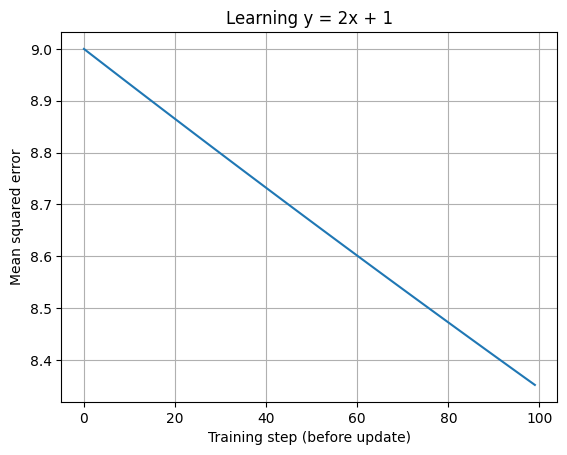

In [191]:
import matplotlib.pyplot as plt

plt.plot(loss_history)
plt.xlabel("Training step (before update)")
plt.ylabel("Mean squared error")
plt.title("Learning y = 2x + 1")
plt.grid(True)
plt.show()

In [192]:
print("Learned weight:", weight.item())
print("Learned bias:", bias.item())

with torch.no_grad():
    new_x = torch.tensor([3.0, 4.0])
    new_predictions = weight * new_x + bias

print("New predictions:", new_predictions)

Learned weight: 0.07843650877475739
Learned bias: 0.019803285598754883
New predictions: tensor([0.2551, 0.3335])


The model predicts, measures error, calculate gradients, and then updates the parameters. In a loop over time, gradients are reset while parameters are preserved to improve and reduce loss over training period.

With the data, initial parameters, and training-step count held constant, smaller learning rates produced slower convergence in this experiment. The model still calculated gradients, but each update changed the parameters less. Given more training steps, the smaller learning rates could approach the same solution.

LR = 0.1
- Learned weight: 2.0
- Learned bias: 0.9999998807907104
- New predictions: tensor([7., 9.])

LR = 0.01
- Learned weight: 1.9662595987319946
- Learned bias: 0.8673803806304932
- New predictions: tensor([6.7662, 8.7324])

LR = 0.0001
- Learned weight: 0.07843650877475739
- Learned bias: 0.019803285598754883
- New predictions: tensor([0.2551, 0.3335])

## 5. Explain it in your own words

Answer without copying the tutorial text:

- **Forward pass:**
This is the model using weights and bias to make a prediction. This is by prediction = weight * x + bias
- **Loss:**
In our example, we used MSE (mean squared error). MSE is the average squared difference between the predictions and targets.
- **Backward pass:**
This is calculated using the chain rule. Gradients describe how much each parameters impactts the loss. This is stored in bias.grad and weight.grad
- **Optimizer step:**
Uses the gradient and learning rate to update parameters.
- **Why gradients are cleared between steps:**
We clear gradients before the next backward pass because PyTorch otherwise adds new gradients to the old ones. The learned weight and bias carry forward

## Before saving

- [ ] **Runtime > Restart session and run all** works top to bottom
- [ ] There are no credentials, private Drive links, or personal data in cells or outputs
- [ ] Save with **File > Save a copy to GitHub** to `notebooks/00_pytorch_basics.ipynb` on `main`
- [ ] Check off the matching items in [issue #4](https://github.com/sidagarwal-labs/LLMs/issues/4)

**Next:** finish autograd and regression before moving on. Then build the bigram model in [issue #5](https://github.com/sidagarwal-labs/LLMs/issues/5); the [stage 1 guide](https://github.com/sidagarwal-labs/LLMs/blob/main/docs/learning-path.md#stage-1-foundations) has the tutorial and completion gate.